In [13]:
%pip install -U langgraph langchain-google-genai python-dotenv

  Using cached langchain_google_genai-4.4.2-py3-none-any.whl.metadata (2.7 kB)
  Using cached filetype-1.2.0-py2.py3-none-any.whl.metadata (6.5 kB)
  Using cached google_genai-2.32.0-py3-none-any.whl.metadata (58 kB)
  Using cached google_auth-2.62.0-py3-none-any.whl.metadata (6.0 kB)
  Using cached tenacity-9.1.4-py3-none-any.whl.metadata (1.2 kB)
  Using cached pyasn1_modules-0.4.2-py3-none-any.whl.metadata (3.5 kB)
  Using cached cryptography-50.0.2-cp311-abi3-win_amd64.whl.metadata (4.4 kB)
  Using cached cffi-2.1.1-cp313-cp313-win_amd64.whl.metadata (2.6 kB)
  Using cached pyasn1-0.6.4-py3-none-any.whl.metadata (8.4 kB)
Using cached langchain_google_genai-4.4.2-py3-none-any.whl (81 kB)
Using cached filetype-1.2.0-py2.py3-none-any.whl (19 kB)
Using cached google_genai-2.32.0-py3-none-any.whl (1.2 MB)
Using cached google_auth-2.62.0-py3-none-any.whl (267 kB)
Using cached tenacity-9.1.4-py3-none-any.whl (28 kB)
Using cached cryptography-50.0.2-cp311-abi3-win_amd64.whl (3.8 MB)
Using 


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
%pip install python-dotenv

  Using cached python_dotenv-1.2.4-py3-none-any.whl.metadata (29 kB)
Using cached python_dotenv-1.2.4-py3-none-any.whl (23 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
from langgraph.graph import StateGraph, MessagesState, START, END
from typing import TypedDict
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI


In [18]:
load_dotenv()

True

# Define LLM

In [20]:
model = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

# Define State

In [8]:
class LLMState(TypedDict):

    question: str
    answer: str

# creating node

In [22]:
def llm_qa(state: LLMState) -> LLMState:

    # extract the question from state
    question = state['question']

    # form a prompt
    prompt = f'Answer the following question : {question}'

    # ask that question to the LLM
    answer = model.invoke(prompt).content

    # update the answer in the state
    state['answer'] = answer

    return state

# Define and compile Graph

In [24]:

graph = StateGraph(LLMState)

# add nodes
graph.add_node('llm_qa',llm_qa)

# add edges
graph.add_edge(START, "llm_qa")
graph.add_edge("llm_qa", END)

# compile
workflow = graph.compile()

## Execute the Graph

In [25]:
initial_state = {'question' : 'who is the creator of python ?'}
final_state = workflow.invoke(initial_state)

print(final_state['answer'])

The creator of Python is **Guido van Rossum**.

He started working on it in the late 1980s and first released it in **1991**.


## Visualize the Graph

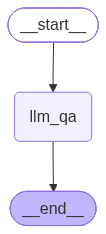

In [26]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())